# 07_track2_volume: Track 2, ticket volume
Track 2a: 7-day-ahead daily forecasts, evaluated on rolling origins. Track 2b: a working-day planning estimate by month. Aggregates only. Needs data/ and statsmodels (pip install statsmodels).

## 1. Build the daily ticket series

In [1]:
import sys, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.append("../src")
from project_config import START, TEST_START, CUT

df = pd.read_pickle("../data/processed/itsm_clean.pkl")
w = df[(df["Open_Time"] >= START) & (df["Open_Time"] < CUT)]
daily = w.set_index("Open_Time").resample("D").size().rename("tickets")
print(len(daily), daily.index.min().date(), daily.index.max().date(), int(daily.sum()))

167 2013-10-01 2014-03-16 42304


## 2. Shape of the series: weekday pattern, quietest days and plot

count    167.0
mean     253.3
std      172.2
min        0.0
25%        7.5
50%      323.0
75%      380.0
max      569.0
Name: tickets, dtype: float64
      mean  median  min  max
Mon  409.0   411.0  282  569
Tue  387.0   382.0  269  476
Wed  323.0   338.0    0  458
Thu  354.0   367.0    2  455
Fri  295.0   290.0  197  357
Sat    9.0     6.0    0   54
Sun    4.0     4.0    1    7
Open_Time
2013-10-26    0
2014-01-01    0
2013-12-25    1
2014-01-04    1
2014-01-05    1
2014-01-12    1
2014-02-02    1
2014-02-09    1
2014-03-09    1
2013-12-08    2
Name: tickets, dtype: int64


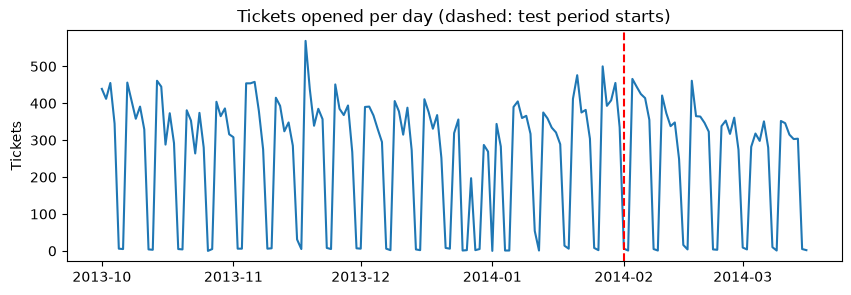

In [2]:
print(daily.describe().round(1))
dow = daily.groupby(daily.index.day_of_week).agg(["mean", "median", "min", "max"]).round(0)
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(dow)
print(daily.nsmallest(10))

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(daily.index, daily.values)
ax.axvline(pd.Timestamp(TEST_START), color="red", linestyle="--")
ax.set_title("Tickets opened per day (dashed: test period starts)")
ax.set_ylabel("Tickets")
plt.show()

## 3. Forecasting models and evaluation helpers
Two baselines (repeat last week, mean of the same weekday over 4 weeks) and Holt-Winters with weekly seasonality, plain and with a damped trend. `run_eval` makes rolling-origin forecasts; `score` reports daily MAE, WAPE, bias and the error on a week's total (MAPE is avoided because weekend counts are tiny).

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
warnings.filterwarnings("ignore", module="statsmodels")

H = 7   # forecast horizon in days

def repeat_last_week(hist):
    return hist.iloc[-7:].to_numpy(dtype=float)

def weekday_mean_4w(hist):
    return hist.iloc[-28:].to_numpy(dtype=float).reshape(4, 7).mean(axis=0)

def holt_winters(hist):
    m = ExponentialSmoothing(hist.astype(float), trend=None, seasonal="add",
                             seasonal_periods=7, initialization_method="estimated").fit()
    return m.forecast(H).to_numpy()

def holt_winters_damped(hist):
    m = ExponentialSmoothing(hist.astype(float), trend="add", damped_trend=True, seasonal="add",
                             seasonal_periods=7, initialization_method="estimated").fit()
    return m.forecast(H).to_numpy()

models = {"Repeat last week": repeat_last_week,
          "Weekday mean, 4 weeks": weekday_mean_4w,
          "Holt-Winters": holt_winters,
          "Holt-Winters, damped trend": holt_winters_damped}

def run_eval(models_, origins_):
    """Rolling-origin forecasts: at each origin day, forecast the next H days from the history up to that day."""
    parts = []
    for t in origins_:
        hist = daily.loc[:t]
        actual = daily.loc[t + pd.Timedelta(days=1): t + pd.Timedelta(days=H)].to_numpy()
        for name, f in models_.items():
            fc = np.clip(f(hist), 0, None)
            parts.append(pd.DataFrame({"model": name, "origin": t, "h": np.arange(1, H + 1),
                                       "actual": actual, "fc": fc}))
    r = pd.concat(parts, ignore_index=True)
    r["abs_err"] = (r["actual"] - r["fc"]).abs()
    return r

def score(r):
    g = r.groupby("model")
    out = pd.DataFrame({"MAE": g["abs_err"].mean(),
                        "WAPE %": g["abs_err"].sum() / g["actual"].sum() * 100,
                        "bias": (g["fc"].sum() - g["actual"].sum()) / g["actual"].count()})
    wk = r.groupby(["model", "origin"]).agg(actual=("actual", "sum"), fc=("fc", "sum"))
    wk["ape"] = (wk["fc"] - wk["actual"]).abs() / wk["actual"] * 100
    out["weekly-total error %"] = wk.groupby("model")["ape"].mean()
    return out.round(2)

## 4. Rolling origins on the test period
Origins run from 31 January to 9 March 2014. At each origin the models see only the past and forecast the next 7 days (38 origins, 266 forecasts per model).

In [4]:
first = pd.Timestamp(TEST_START) - pd.Timedelta(days=1)
last = daily.index[-1] - pd.Timedelta(days=H)
origins = daily.index[(daily.index >= first) & (daily.index <= last)]
print(len(origins), origins[0].date(), origins[-1].date())

res = run_eval(models, origins)
print(res.groupby("model").size())

38 2014-01-31 2014-03-09
model
Holt-Winters                  266
Holt-Winters, damped trend    266
Repeat last week              266
Weekday mean, 4 weeks         266
dtype: int64


## 5. Scores: daily error, bias, weekly-total error and error by horizon

In [5]:
print(score(res))
print(res.pivot_table(index="h", columns="model", values="abs_err", aggfunc="mean").round(1))

                              MAE  WAPE %   bias  weekly-total error %
model                                                                 
Holt-Winters                30.65   12.31  13.01                  8.15
Holt-Winters, damped trend  30.58   12.28  13.19                  8.12
Repeat last week            31.36   12.59  12.44                  7.99
Weekday mean, 4 weeks       33.22   13.34  22.66                 11.79
model  Holt-Winters  Holt-Winters, damped trend  Repeat last week  \
h                                                                   
1              30.8                        30.8              30.8   
2              32.0                        31.9              31.5   
3              33.0                        32.8              31.9   
4              30.6                        30.4              32.3   
5              31.2                        31.2              31.6   
6              28.4                        28.4              31.2   
7              28.5   

### Result
Rule set in advance: a model counts as better only if its daily WAPE is at least 10% lower than both baselines and its weekly-total error is also lower.
On the test origins no model met it: repeat last week 12.59% daily WAPE and 7.99% weekly-total error; Holt-Winters 12.31% and 8.15%; Holt-Winters with damped trend 12.28% and 8.12%; 4-week weekday mean 13.34% and 11.79%. Repeat last week is kept as the simple, adequate model. The 38 origins overlap, so there are about 6 independent weeks of evidence.

## 6. Figure: forecasts made 7 days ahead, test period

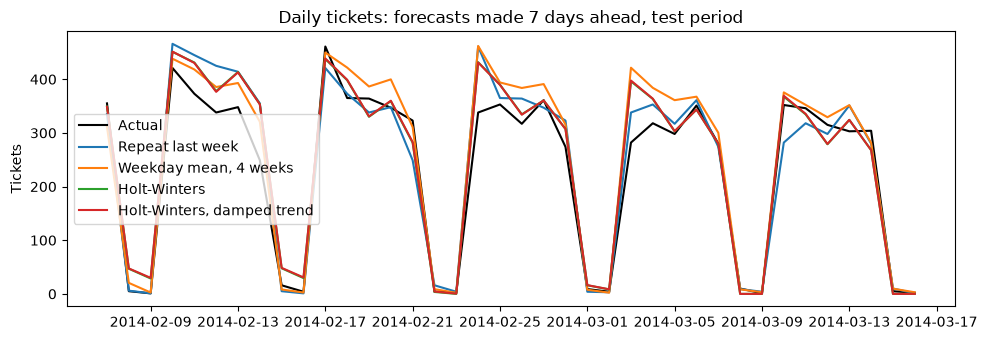

In [6]:
import os
os.makedirs("../reports/figures", exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 3.5))
act = res[(res["model"] == "Repeat last week") & (res["h"] == 7)]
ax.plot(act["origin"] + pd.Timedelta(days=7), act["actual"], color="black", label="Actual")
for name in models:
    d = res[(res["model"] == name) & (res["h"] == 7)]
    ax.plot(d["origin"] + pd.Timedelta(days=7), d["fc"], label=name)
ax.set_title("Daily tickets: forecasts made 7 days ahead, test period")
ax.set_ylabel("Tickets")
ax.legend()
fig.tight_layout()
fig.savefig("../reports/figures/track2_volume_forecast.png", dpi=150)
plt.show()

## 7. Where the error sits: by weekday and by date (repeat last week)

In [7]:
res["target"] = res["origin"] + pd.to_timedelta(res["h"], unit="D")
res["dow"] = res["target"].dt.day_name().str[:3]
by = res.pivot_table(index="dow", columns="model", values="abs_err", aggfunc="mean").round(1)
print(by.reindex(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]))

b = (res[res["model"] == "Repeat last week"].groupby("target")
        .agg(actual=("actual", "first"), forecast=("fc", "mean"), abs_err=("abs_err", "mean")))
print(b.sort_values("abs_err", ascending=False).head(10).round(0))

model  Holt-Winters  Holt-Winters, damped trend  Repeat last week  \
dow                                                                 
Mon            60.2                        60.2              64.2   
Tue            38.4                        38.0              33.3   
Wed            30.1                        29.9              37.4   
Thu            21.9                        21.7              28.3   
Fri            30.0                        29.9              48.9   
Sat            18.2                        18.3               5.8   
Sun            15.8                        16.0               1.6   

model  Weekday mean, 4 weeks  
dow                           
Mon                     61.8  
Tue                     43.4  
Wed                     46.0  
Thu                     36.9  
Fri                     36.7  
Sat                      6.3  
Sun                      1.5  
            actual  forecast  abs_err
target                               
2014-02-24     338     

## 8. Exploration: damped trend and a weekend hybrid, checked on earlier origins
The hybrid (damped Holt-Winters on weekdays, repeat last week on weekends) was designed after inspecting test-period errors, so it is also evaluated on earlier origins (1 December to 24 January, with and without the 17 December to 8 January holiday window). It did not meet the rule set in advance and is rejected.

In [8]:
def hybrid(hist):
    fc = np.clip(holt_winters_damped(hist), 0, None)
    naive = repeat_last_week(hist)
    days = pd.date_range(hist.index[-1] + pd.Timedelta(days=1), periods=H)
    return np.where(np.asarray(days.day_of_week) >= 5, naive, fc)

models2 = {**models, "Damped HW weekdays + repeat on weekends": hybrid}

pre_origins = daily.index[(daily.index >= "2013-12-01") & (daily.index <= "2014-01-24")]
noh = pre_origins[(pre_origins < "2013-12-17") | (pre_origins > "2014-01-08")]
print("Earlier origins:", len(pre_origins), "| without the holiday window:", len(noh))
print(score(run_eval(models2, pre_origins)))
print(score(run_eval(models2, noh)))
print(score(run_eval(models2, origins)))

Earlier origins: 55 | without the holiday window: 32
                                           MAE  WAPE %  bias  \
model                                                          
Damped HW weekdays + repeat on weekends  52.84   22.70  3.41   
Holt-Winters                             50.97   21.90  2.93   
Holt-Winters, damped trend               52.86   22.71  3.09   
Repeat last week                         55.87   24.01 -3.71   
Weekday mean, 4 weeks                    61.58   26.46  1.36   

                                         weekly-total error %  
model                                                          
Damped HW weekdays + repeat on weekends                 23.58  
Holt-Winters                                            22.09  
Holt-Winters, damped trend                              23.45  
Repeat last week                                        23.76  
Weekday mean, 4 weeks                                   29.85  
                                           MAE  WA

## 9. Track 2b: monthly volume per weekday (opened and closed)
Closed counts are complete for all six months (the extract is cut by close date); opened counts are censored at the end of March.

In [9]:
def monthly(col):
    return df.groupby(df[col].dt.to_period("M")).size().loc["2013-10":"2014-03"]

m = pd.DataFrame({"opened": monthly("Open_Time"), "closed": monthly("Close_Time")})
m["weekdays"] = [len(pd.bdate_range(p.start_time.normalize(), p.end_time.normalize())) for p in m.index]
m["opened/weekday"] = (m["opened"] / m["weekdays"]).round(0)
m["closed/weekday"] = (m["closed"] / m["weekdays"]).round(0)
print(m)

         opened  closed  weekdays  opened/weekday  closed/weekday
2013-10    8606    8544        23           374.0           371.0
2013-11    8128    8052        21           387.0           383.0
2013-12    6743    7013        22           306.0           319.0
2014-01    8270    8210        23           360.0           357.0
2014-02    7377    7542        20           369.0           377.0
2014-03    6332    7245        21           302.0           345.0


## 10. Category shares of opened tickets by month

In [10]:
sh = (w.assign(month=w["Open_Time"].dt.to_period("M"))
        .groupby(["month", "CI_Cat"]).size().unstack(fill_value=0))
top = w["CI_Cat"].value_counts().head(5).index
print(sh.div(sh.sum(axis=1), axis=0)[top].round(3))

CI_Cat   application  subapplication  computer  storage  hardware
month                                                            
2013-10        0.707           0.167     0.086    0.010     0.008
2013-11        0.715           0.155     0.084    0.016     0.005
2013-12        0.710           0.162     0.085    0.017     0.004
2014-01        0.695           0.173     0.071    0.016     0.018
2014-02        0.708           0.174     0.069    0.016     0.008
2014-03        0.675           0.175     0.088    0.018     0.017


## 11. Backtest: weekdays times the running rate
A month's volume is predicted as the number of weekdays in it times the average opened tickets per weekday in the earlier months. Three test months only (March is excluded: censored).

In [11]:
mm = m.loc["2013-10":"2014-02"]
rows = []
for i in range(2, len(mm)):
    rate = mm["opened"].iloc[:i].sum() / mm["weekdays"].iloc[:i].sum()
    pred = rate * mm["weekdays"].iloc[i]
    rows.append({"month": str(mm.index[i]), "predicted": round(pred), "actual": int(mm["opened"].iloc[i]),
                 "error %": round((pred / mm["opened"].iloc[i] - 1) * 100, 1)})
print(pd.DataFrame(rows))

     month  predicted  actual  error %
0  2013-12       8367    6743     24.1
1  2014-01       8181    8270     -1.1
2  2014-02       7134    7377     -3.3
